# BSISO1 phase composites: Ekman transport, MSE and Ekman advection

Composites by BSISO1 phase (active days, amplitude > 1) from `bsiso_phase.jl`, file `ekman_bsiso1_phase_2012-2020.nc`. The first figures show one phase `p`, as in `ekman_plots.ipynb` for a pentad; the last two show zonal wind stress and surface-air MSE for all 8 phases, to pick out the phases of interest (e.g. monsoon onset). The library `ekman_V_ma_mo_plot.jl` is loaded with Revise `includet`.

Kernel: "Julia", started with `--project=@.`, which finds `plot/Project.toml`.

In [1]:
using Revise
includet("ekman_V_ma_mo_plot.jl")

    CondaPkg Found dependencies: /home/ceoas/deszoeks/.julia/packages/CondaPkg/Pc7ZA/CondaPkg.toml
    CondaPkg Found dependencies: /home/ceoas/deszoeks/.julia/packages/PythonCall/trYos/CondaPkg.toml
    CondaPkg Found dependencies: /home/ceoas/deszoeks/.julia/packages/PythonPlot/96RVm/CondaPkg.toml
    CondaPkg Initialising pixi
             │ /home/ceoas/deszoeks/.julia/artifacts/8429d049f6c01106c62971e9540e146dc068df25/bin/pixi
             │ init
             │ --format pixi
             └ /ceoas/deszoeks/projects/ekman-astz/plot/.CondaPkg
Created /ceoas/deszoeks/projects/ekman-astz/plot/.CondaPkg/pixi.toml
    CondaPkg Wrote /ceoas/deszoeks/projects/ekman-astz/plot/.CondaPkg/pixi.toml
             │ [dependencies]
             │ matplotlib = ">=1"
             │ openssl = ">=3, <3.6"
             │ 
             │     [dependencies.python]
             │     version = ">=3.10,!=3.14.0,!=3.14.1,<4"
             │     build = "*cp*"
             │     channel = "conda-forge"
       

"K kg m\$^{-2}\$ s\$^{-1}\$"

## Data
Phase `p` in the region `lonlim`, `latlim`; only that region is read. `d`: composite fields as read; `f`: the fields plotted. `ndays`: the number of active days composited in a phase (the maximum of `nobs_taux` over the region). `Ro_rad` curtails M near the equator after compositing (see `ekman_fields`).

In [3]:
file = "../ekman_bsiso1_phase_2012-2020.nc"
p = 4                                # BSISO1 phase (1-8)
lonlim, latlim = (40, 110), (-5, 30) # degrees: Indian Ocean; only this region is read
Ro_rad = 250e3 # m, curtail M by r = 1 - exp(-y^2/Ro_rad^2) near the equator (plotting only)
advlim = 180   # W m^-2, color limit for the enthalpy advection panels
phases = NCDataset(nc -> nc["phase"][:], file) # 1:8
ndays(k) = Int(maximum(read_group(file, k; vars=("nobs_taux",), lonlim, latlim).nobs_taux))
k = findfirst(==(p), phases)
d = read_group(file, k; lonlim, latlim)
f = ekman_fields(d; Ro_rad)
figtitle = "$(basename(file)): BSISO1 phase $p, $(ndays(k)) days (Ro_rad = $(Ro_rad/1e3) km)"
size(f.Mx), keys(f)

((281, 141), (:lon, :lat, :Mx, :My, :m_a, :m_o, :dmodx, :dmody, :dmadx, :dmady, :advT_o, :advT_a, :adv_o, :adv_a, :sdiv_o, :sdiv_a, :flux_o, :flux_a, :r, :land))

## Ekman transport, surface-air MSE and ocean-surface enthalpy, phase `p`
Each figure is a list of `panel(x, title, units; cmap="RdBu_r", kw...)`, filled in row by row (2 columns). `kw` go to `pcolormesh`; without vmin/vmax the limits are ±98th percentile of |x|. The MSE limits are copied from the pentad notebook; adjust them for the phase.

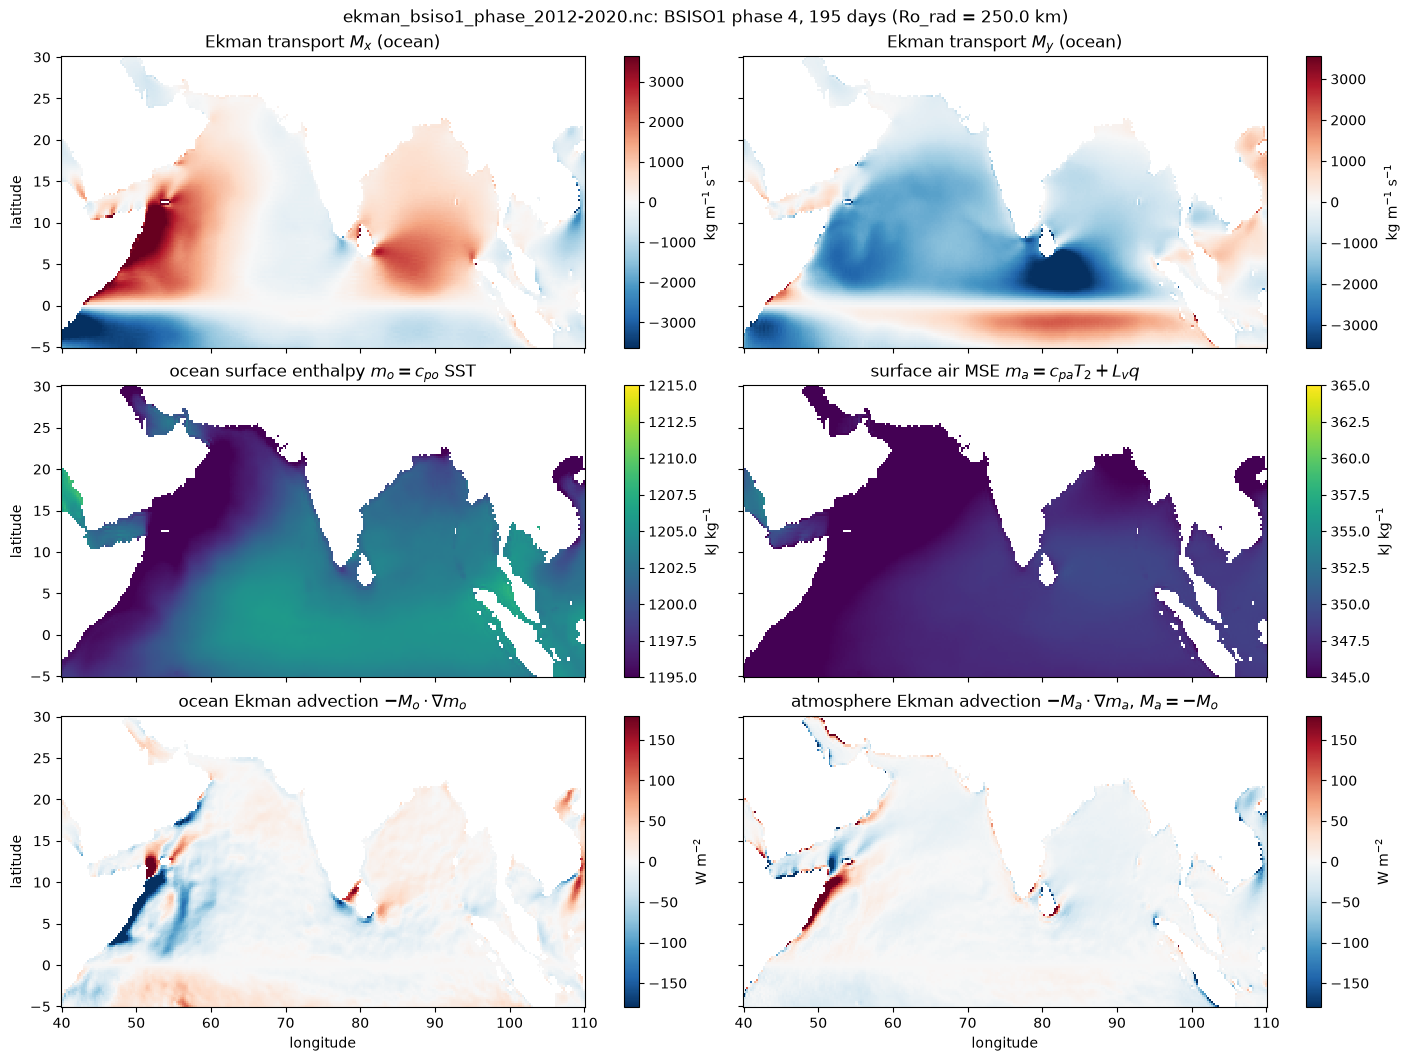

In [4]:
panels1 = [
    panel(f.Mx, raw"Ekman transport $M_x$ (ocean)", raw"kg m$^{-1}$ s$^{-1}$"),
    panel(f.My, raw"Ekman transport $M_y$ (ocean)", raw"kg m$^{-1}$ s$^{-1}$"),
    panel(f.m_o ./ 1e3, raw"ocean surface enthalpy $m_o = c_{po}$ SST", raw"kJ kg$^{-1}$"; cmap="viridis", vmin=1195, vmax=1215),
    panel(f.m_a ./ 1e3, raw"surface air MSE $m_a = c_{pa} T_2 + L_v q$", raw"kJ kg$^{-1}$"; cmap="viridis", vmin=345, vmax=365),
    panel(f.adv_o, raw"ocean Ekman advection $-M_o \cdot \nabla m_o$", flux_units; vmin=-advlim, vmax=advlim),
    panel(f.adv_a, raw"atmosphere Ekman advection $-M_a \cdot \nabla m_a$, $M_a = -M_o$", flux_units; vmin=-advlim, vmax=advlim)
    ]    
fig1, axs1 = plot_panels(f.lon, f.lat, panels1; land=f.land, suptitle=figtitle);

## Ocean and atmosphere Ekman advection and their sum, phase `p`
Columns: ocean, atmosphere, sum. Rows: temperature (mass-weighted, K kg m$^{-2}$ s$^{-1}$) and (moist) enthalpy, W m$^{-2}$. Each row shares its color limits.

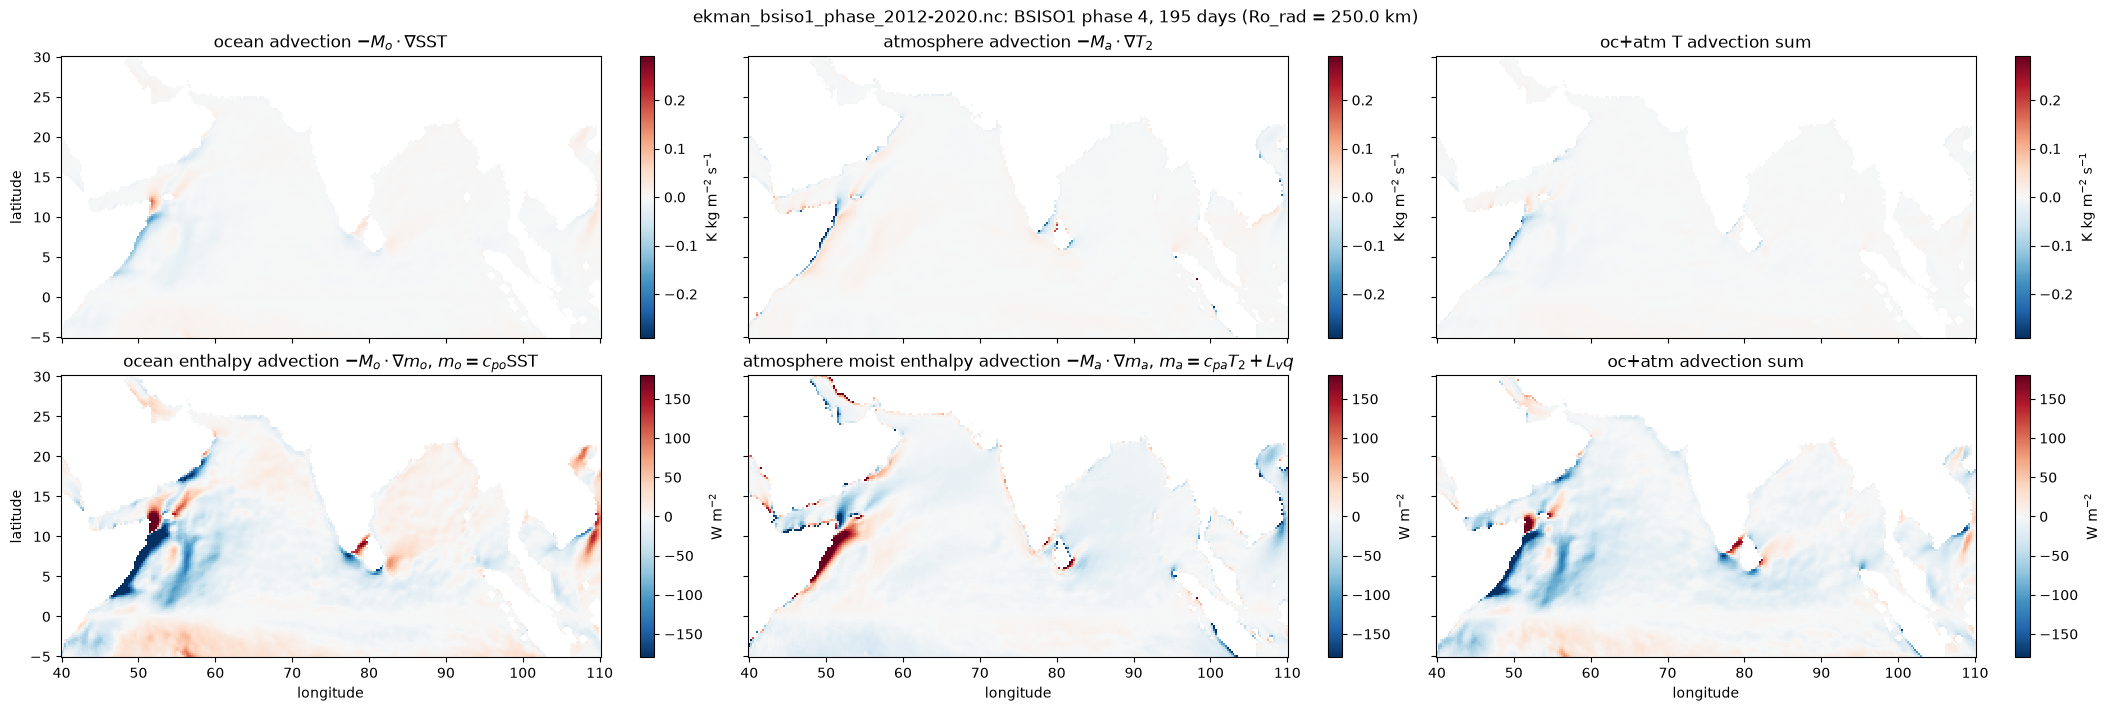

In [5]:
Tlim = maximum(symlim, (f.advT_o, f.advT_a)) # shared by the temperature row
Hlim = advlim                                # W m^-2, shared by the enthalpy row
panels_adv = [
    panel(f.advT_o, raw"ocean advection $-M_o \cdot \nabla$SST", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.advT_a, raw"atmosphere advection $-M_a \cdot \nabla T_2$", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.advT_o .+ f.advT_a, "oc+atm T advection sum", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.adv_o, raw"ocean enthalpy advection $-M_o \cdot \nabla m_o$, $m_o = c_{po}$SST", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f.adv_a, raw"atmosphere moist enthalpy advection $-M_a \cdot \nabla m_a$, $m_a = c_{pa}T_2 + L_v q$", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f.adv_o .+ f.adv_a, "oc+atm advection sum", flux_units; vmin=-Hlim, vmax=Hlim)]
fig_adv, axs_adv = plot_panels(f.lon, f.lat, panels_adv; ncols=3, land=f.land, suptitle=figtitle);

## Cancellation of Ekman divergence and flux divergence tendency, phase `p`
The flux form $-\nabla\cdot(M m)$ is from the saved composites of $s\tau_x$, $s\tau_y$; $m \nabla\cdot M = $ adv $-$ flux.

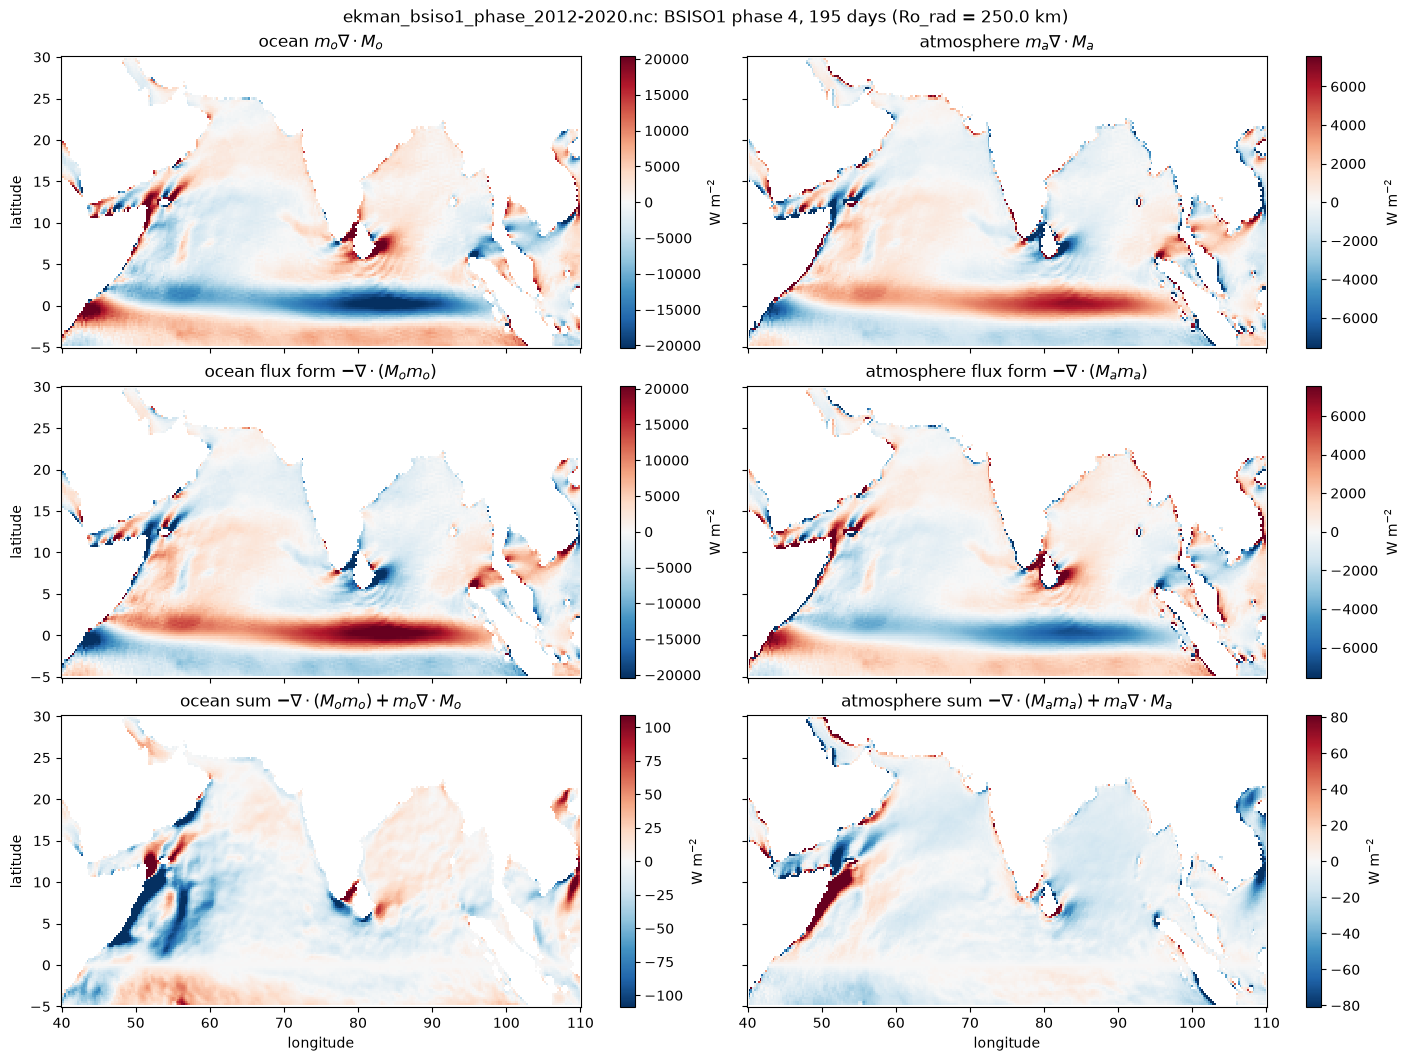

In [6]:
panels3 = [
    panel(f.sdiv_o, raw"ocean $m_o \nabla \cdot M_o$", flux_units),
    panel(f.sdiv_a, raw"atmosphere $m_a \nabla \cdot M_a$", flux_units),
    panel(f.flux_o, raw"ocean flux form $-\nabla \cdot (M_o m_o)$", flux_units),
    panel(f.flux_a, raw"atmosphere flux form $-\nabla \cdot (M_a m_a)$", flux_units),
    panel(f.flux_o.+f.sdiv_o, raw"ocean sum $-\nabla \cdot (M_o m_o) + m_o \nabla \cdot M_o$", flux_units),
    panel(f.flux_a.+f.sdiv_a, raw"atmosphere sum $-\nabla \cdot (M_a m_a) + m_a \nabla \cdot M_a$", flux_units)]
fig3, axs3 = plot_panels(f.lon, f.lat, panels3; land=f.land, suptitle=figtitle);

## All 8 phases: zonal wind stress and surface-air MSE
Read all 8 phases at once, only what these maps need (`taux`, `sst` for the land mask, `t2`, `q`, `nobs_taux`); each variable is lon x lat x phase, indexed `dp[:taux][i, j, q]` (`dp.lon[i]`, `dp.lat[j]`, phase `q`). `anomp(:var)` is a field minus its mean over the 8 phases. All 8 panels of a figure share one color scale; the panel titles give the number of active days in each phase.

In [24]:
dp = read_group(file, 1:8; vars=("taux", "sst", "t2", "q", "nobs_taux"), lonlim, latlim) # each lon x lat x phase
@assert dp.dimval == 1:8 # index q along the third dimension is phase q
dp = merge(dp, (; ma = @. (c_pa*dp.t2 + Lv*dp.q) / 1e3)) # surface-air MSE m_a = c_pa T_2 + L_v q, kJ/kg
# anomalies
using Statistics
mn_taux = mean(dp.taux; dims=3)[:, :, 1]               # lon x lat mean over the 8 phases
anomp(var::Symbol) = dp[var] .- mean(dp[var]; dims=3)  # lon x lat x phase, departure from the 8-phase mean
anomp(:taux)

8-element Vector{Matrix{Float64}}:
 [-0.009880075856926851 -0.008605271839769557 … 0.0027960982406511903 0.002951108035631478; -0.008793320812401362 -0.008586647345509846 … 0.002503027440980077 0.0026508558075875044; … ; -0.004228516496368684 -0.009158703323919326 … -0.012495186150772497 -0.01290401368169114; -0.004697710071923211 -0.006451050052419305 … -0.012893498736957554 -0.01328317864681594]
 [-0.015082652840646915 -0.010311206831829622 … 0.0051486153388395905 0.004411276546306908; -0.012782346879248507 -0.0099207873645355 … 0.004748082021251321 0.004155753878876567; … ; 0.018079224610119127 0.028081407013814896 … -0.017268147290451452 -0.01754483877448365; 0.02380322219687514 0.023976672673597932 … -0.017562740344146732 -0.0178151395812165]
 [0.003519542355206795 0.002472247666446492 … 0.004648239002563059 0.004683866281993687; 0.0025455583090661094 0.0025286807140219025 … 0.004869517171755433 0.004829660756513476; … ; 0.02798382284527179 0.039694435603450984 … 0.006658146186964

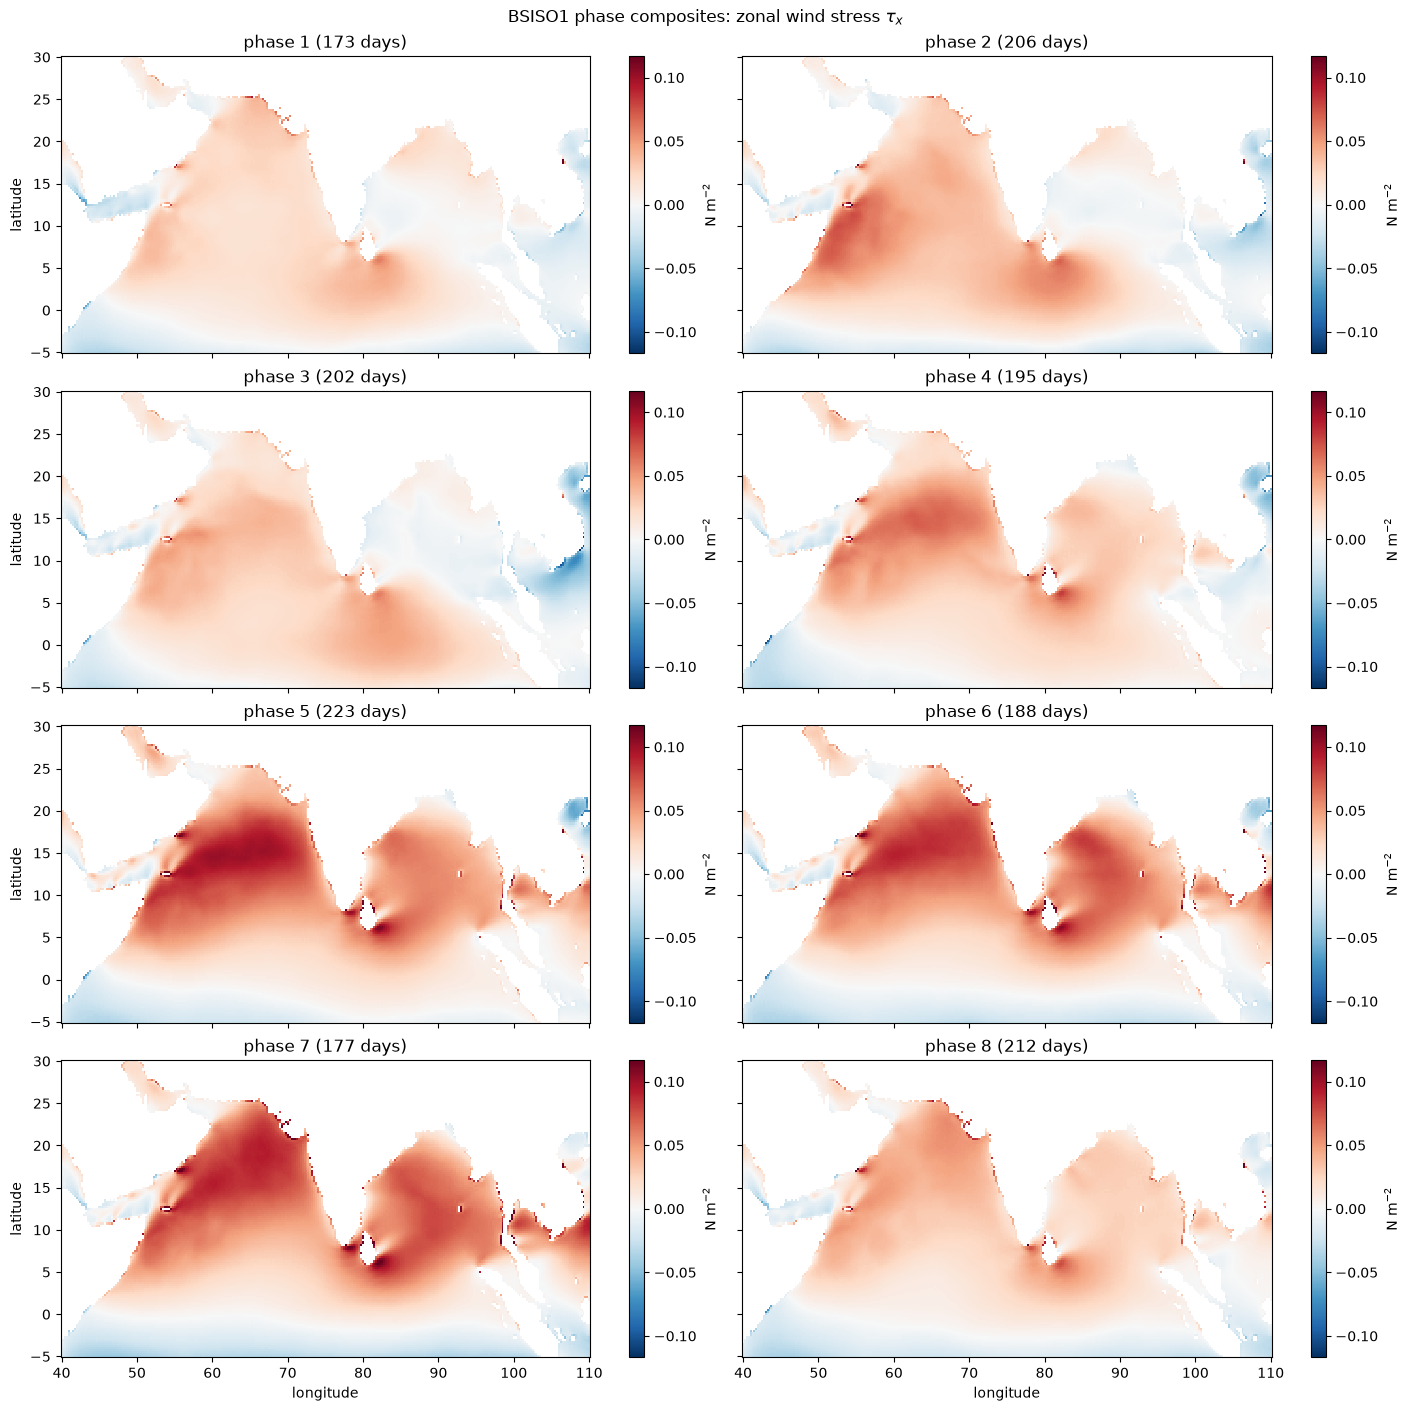

In [10]:
lon, lat, land = dp.lon, dp.lat, isnan.(dp.sst[:, :, 1])
daytitle(q) = "phase $q ($(Int(maximum(dp.nobs_taux[:, :, q]))) days)"
taulim = maximum(q -> symlim(dp.taux[:, :, q]), 1:8)/2 # N m^-2, shared by all phases
panels_tau = [panel(dp.taux[:, :, q], daytitle(q), raw"N m$^{-2}$"; vmin=-taulim, vmax=taulim) for q in 1:8]
fig_tau, axs_tau = plot_panels(lon, lat, panels_tau; 
    ncols=2, land, suptitle=raw"BSISO1 phase composites: zonal wind stress $\tau_x$");

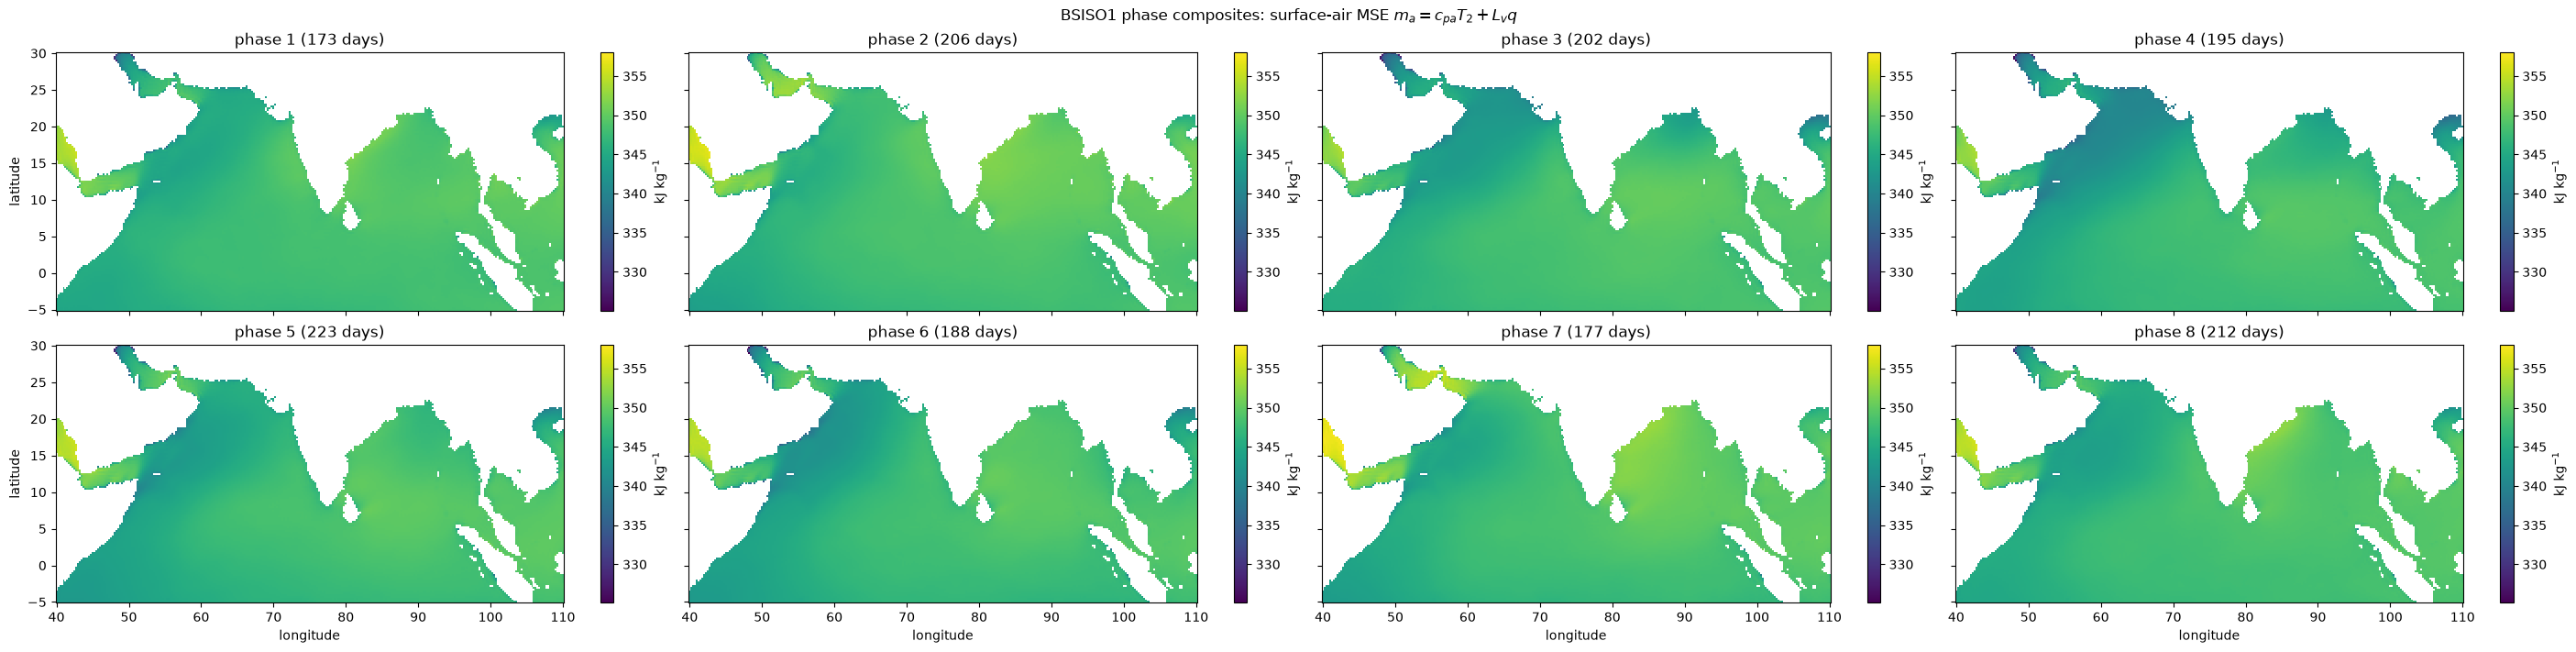

In [8]:
malim = extrema(filter(isfinite, dp.ma[.!land, :])) # over ocean, all phases
panels_ma = [panel(dp.ma[:, :, q], daytitle(q), raw"kJ kg$^{-1}$"; cmap="viridis", vmin=malim[1], vmax=malim[2]) for q in 1:8]
fig_ma, axs_ma = plot_panels(lon, lat, panels_ma; ncols=4, land, suptitle=raw"BSISO1 phase composites: surface-air MSE $m_a = c_{pa} T_2 + L_v q$");

In [ ]:
ma_anom = anomp(:ma) # kJ/kg, phase minus 8-phase mean
alim = symlim(ma_anom[.!land, :])
panels_ma_anom = [panel(ma_anom[:, :, q], daytitle(q), raw"kJ kg$^{-1}$"; vmin=-alim, vmax=alim) for q in 1:8]
fig_ma_anom, axs_ma_anom = plot_panels(lon, lat, panels_ma_anom; ncols=4, land, suptitle=raw"BSISO1 phase composites: surface-air MSE anomaly from the 8-phase mean");

## Save figures

In [ ]:
# fig1.savefig("bsiso_V_ma_mo_phase$p.png")
# fig_adv.savefig("bsiso_adv_sum_phase$p.png")
# fig3.savefig("bsiso_sdiv_flux_phase$p.png")
# fig_tau.savefig("bsiso_taux_phases.png")
# fig_ma.savefig("bsiso_ma_phases.png")
# fig_ma_anom.savefig("bsiso_ma_anom_phases.png")